# Lab 1 - Part 1 : Regression with PyTorch (NYSE dataset)

**Goal:** predict the next day closing price of a stock using a simple MLP (DNN) built with PyTorch.

Dataset: https://www.kaggle.com/datasets/dgawlik/nyse

Steps:
1. Exploratory Data Analysis (EDA)
2. DNN architecture with PyTorch
3. Hyper-parameter search with `GridSearchCV` (sklearn) through `skorch`
4. Loss / Epochs and Accuracy / Epochs curves (train vs test)
5. Regularization (Dropout, L2 weight decay, Batch Norm, Early stopping) and comparison

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from skorch import NeuralNetRegressor

torch.manual_seed(42)
np.random.seed(42)
sns.set_style("whitegrid")

DATA_DIR = "../data/nyse/"

## 1. Exploratory Data Analysis

The dataset has 4 files. We mainly use `prices-split-adjusted.csv` (prices corrected for stock splits)
and `securities.csv` (company name and sector).

In [2]:
prices = pd.read_csv(DATA_DIR + "prices-split-adjusted.csv", parse_dates=["date"])
securities = pd.read_csv(DATA_DIR + "securities.csv")

print(prices.shape)
prices.head()

(851264, 7)


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


In [3]:
prices.info()

<class 'pandas.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[us]
 1   symbol  851264 non-null  str           
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[us](1), float64(5), str(1)
memory usage: 45.5 MB


In [4]:
prices.describe()

,date,open,close,low,high,volume
count,851264,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,2013-07-21 02:56:29.294038,64.993618,65.011913,64.336541,65.639748,5.415113e+06
min,2010-01-04 00:00:00,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,2011-10-19 00:00:00,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,2013-08-02 00:00:00,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,2015-04-24 00:00:00,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,2016-12-30 00:00:00,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08
std,NaN,75.203893,75.201216,74.459518,75.906861,1.249468e+07


In [5]:
# missing values and duplicates
print("Missing values:\n", prices.isnull().sum())
print("Duplicated rows:", prices.duplicated().sum())
print("Number of companies:", prices["symbol"].nunique())
print("Period:", prices["date"].min().date(), "->", prices["date"].max().date())

Missing values:
 date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64
Duplicated rows: 0
Number of companies: 501
Period: 2010-01-04 -> 2016-12-30


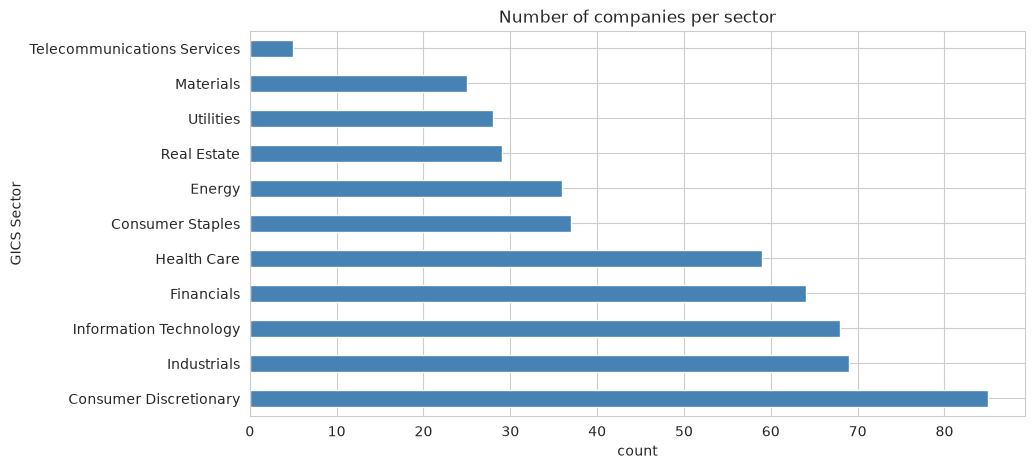

In [6]:
# how many companies per sector
plt.figure(figsize=(10, 5))
securities["GICS Sector"].value_counts().plot(kind="barh", color="steelblue")
plt.title("Number of companies per sector")
plt.xlabel("count")
plt.show()

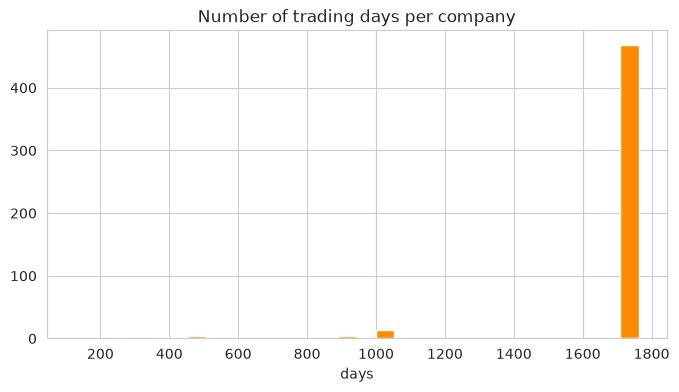

In [7]:
# number of trading days available per company (some companies entered the index later)
days_per_symbol = prices.groupby("symbol").size()
plt.figure(figsize=(8, 4))
plt.hist(days_per_symbol, bins=30, color="darkorange")
plt.title("Number of trading days per company")
plt.xlabel("days")
plt.show()

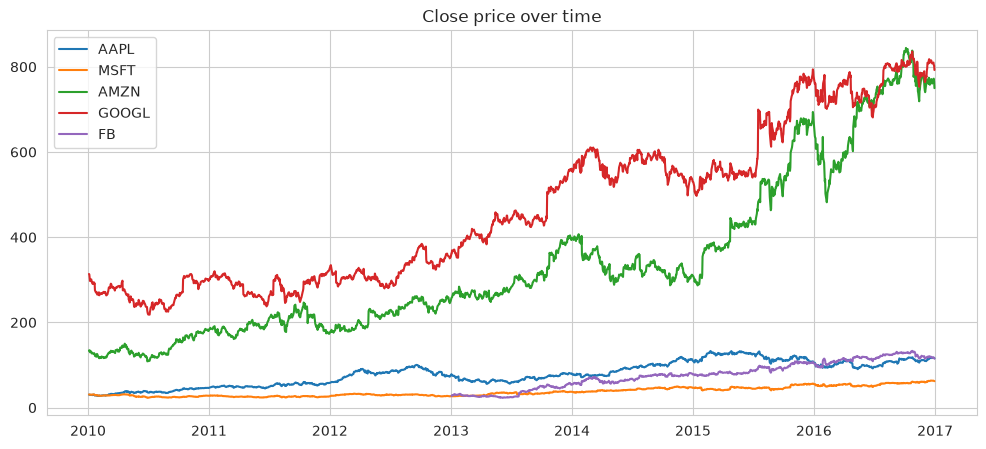

In [8]:
# closing price of a few big companies
plt.figure(figsize=(12, 5))
for s in ["AAPL", "MSFT", "AMZN", "GOOGL", "FB"]:
    d = prices[prices["symbol"] == s]
    plt.plot(d["date"], d["close"], label=s)
plt.title("Close price over time")
plt.legend()
plt.show()

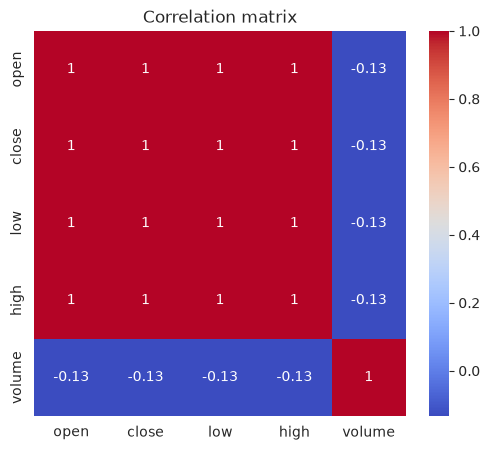

In [9]:
# correlation between the numeric columns (all companies)
plt.figure(figsize=(6, 5))
sns.heatmap(prices[["open", "close", "low", "high", "volume"]].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

`open`, `close`, `low` and `high` are almost perfectly correlated (≈1). Using them to predict the close of the
**same day** would be too easy (data leakage), so the task we choose is: **predict tomorrow's close from the
last 10 closing prices**. We work on one company, Apple (AAPL), to keep things simple.

(1762, 7)


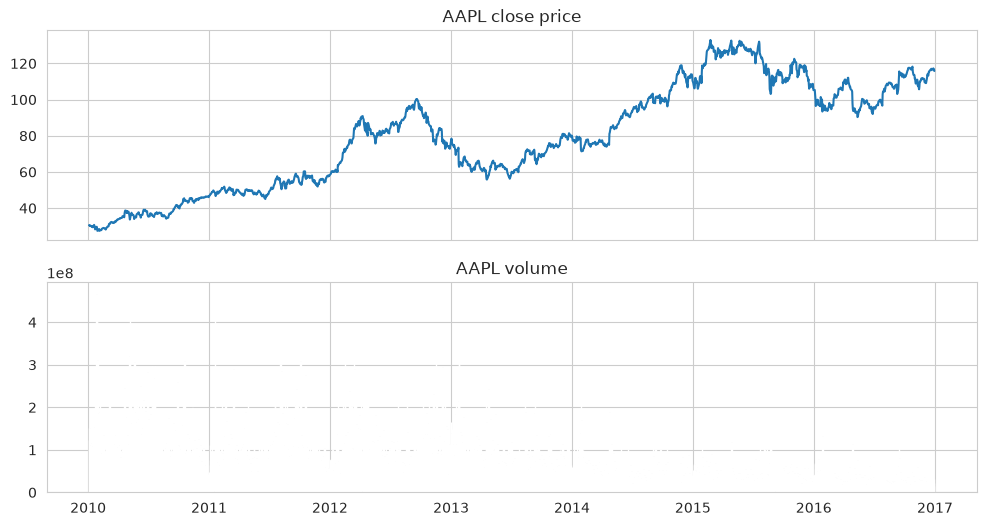

In [10]:
aapl = prices[prices["symbol"] == "AAPL"].sort_values("date").reset_index(drop=True)
print(aapl.shape)

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(aapl["date"], aapl["close"])
ax[0].set_title("AAPL close price")
ax[1].bar(aapl["date"], aapl["volume"], color="gray")
ax[1].set_title("AAPL volume")
plt.show()

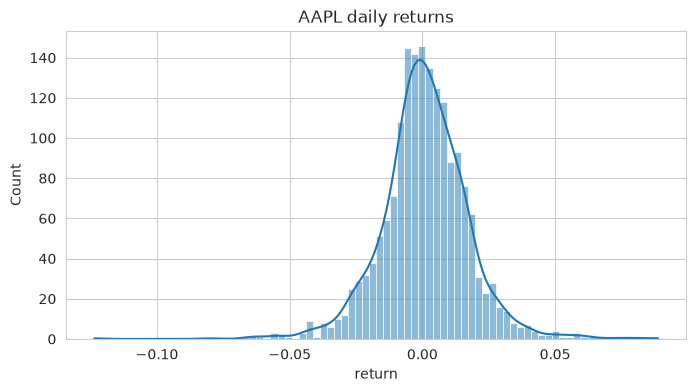

mean return: 0.0008931506012020026  std: 0.01651765852219699


In [11]:
# daily returns distribution
aapl["return"] = aapl["close"].pct_change()
plt.figure(figsize=(8, 4))
sns.histplot(aapl["return"].dropna(), bins=80, kde=True)
plt.title("AAPL daily returns")
plt.show()
print("mean return:", aapl["return"].mean(), " std:", aapl["return"].std())

## Data preparation

- Sliding window: input = 10 previous closes, target = next close.
- Chronological split (80% train / 20% test) - no shuffle, because it's a time series.
- MinMaxScaler fitted **only on train** to avoid leakage.

In [12]:
WINDOW = 10

scaler = MinMaxScaler()
close = aapl["close"].values.reshape(-1, 1)
split = int(len(close) * 0.8)
scaler.fit(close[:split])
close_scaled = scaler.transform(close).flatten()

X, y = [], []
for i in range(WINDOW, len(close_scaled)):
    X.append(close_scaled[i - WINDOW:i])
    y.append(close_scaled[i])
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32).reshape(-1, 1)

split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]
dates_test = aapl["date"].values[WINDOW:][split:]
print(X_train.shape, X_test.shape)

(1401, 10) (351, 10)


## 2. DNN architecture

A simple MLP: `Linear -> ReLU` repeated, then one output neuron (no activation, it's regression).
The number of layers / neurons is a parameter so we can tune it with GridSearch.

In [13]:
class MLPRegressor(nn.Module):
    def __init__(self, n_inputs=WINDOW, hidden=(64, 32), dropout=0.0, batchnorm=False):
        super().__init__()
        layers = []
        prev = n_inputs
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


print(MLPRegressor())

MLPRegressor(
  (net): Sequential(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 3. GridSearch for the hyper-parameters

sklearn's `GridSearchCV` needs an sklearn-like estimator, so we wrap the PyTorch model with **skorch**.
We use `TimeSeriesSplit` (3 folds) as cross-validation, so the validation fold is always after the train fold.

In [14]:
net = NeuralNetRegressor(
    MLPRegressor,
    criterion=nn.MSELoss,
    batch_size=32,
    train_split=None,   # GridSearchCV does the validation
    verbose=0,
)

param_grid = {
    "module__hidden": [(32,), (64, 32), (128, 64, 32)],
    "optimizer": [torch.optim.Adam, torch.optim.SGD],
    "lr": [0.01, 0.001],
    "max_epochs": [50, 100],
}

gs = GridSearchCV(net, param_grid, cv=TimeSeriesSplit(n_splits=3), scoring="neg_mean_squared_error", n_jobs=-1)
gs.fit(X_train, y_train)

print("Best params:", gs.best_params_)
print("Best CV MSE:", -gs.best_score_)

Best params: {'lr': 0.01, 'max_epochs': 100, 'module__hidden': (64, 32), 'optimizer': <class 'torch.optim.adam.Adam'>}
Best CV MSE: 0.0006716070735516647


In [15]:
results = pd.DataFrame(gs.cv_results_)
results["mse"] = -results["mean_test_score"]
results[["param_module__hidden", "param_optimizer", "param_lr", "param_max_epochs", "mse"]] \
    .sort_values("mse").head(10)

,param_module__hidden,param_optimizer,param_lr,param_max_epochs,mse
8,"(64, 32)",<class 'torch.optim.adam.Adam'>,0.010,100,0.000672
0,"(32,)",<class 'torch.optim.adam.Adam'>,0.010,50,0.000994
6,"(32,)",<class 'torch.optim.adam.Adam'>,0.010,100,0.001067
18,"(32,)",<class 'torch.optim.adam.Adam'>,0.001,100,0.003096
20,"(64, 32)",<class 'torch.optim.adam.Adam'>,0.001,100,0.003881
4,"(128, 64, 32)",<class 'torch.optim.adam.Adam'>,0.010,50,0.006151
12,"(32,)",<class 'torch.optim.adam.Adam'>,0.001,50,0.007376
16,"(128, 64, 32)",<class 'torch.optim.adam.Adam'>,0.001,50,0.008131
10,"(128, 64, 32)",<class 'torch.optim.adam.Adam'>,0.010,100,0.008591
14,"(64, 32)",<class 'torch.optim.adam.Adam'>,0.001,50,0.010746


## 4. Training the best model and plotting Loss / Accuracy per epoch

For regression there is no "accuracy" like in classification. We use the **R² score** as the
accuracy metric (1 = perfect prediction, 0 = as good as predicting the mean).

We write a small training loop to record train and test values at every epoch.

In [16]:
def train_model(model, optimizer, X_train, y_train, X_test, y_test, epochs, batch_size=32,
                patience=None):
    """Train the model and return the history (loss and R2 for train and test).
    If patience is given, stop when the test loss doesn't improve for `patience` epochs (early stopping)."""
    loss_fn = nn.MSELoss()
    Xtr, ytr = torch.tensor(X_train), torch.tensor(y_train)
    Xte, yte = torch.tensor(X_test), torch.tensor(y_test)
    history = {"train_loss": [], "test_loss": [], "train_r2": [], "test_r2": []}
    best_loss, best_state, wait = float("inf"), None, 0

    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch_size):
            idx = perm[i:i + batch_size]
            if len(idx) < 2:  # BatchNorm needs at least 2 samples
                continue
            optimizer.zero_grad()
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            p_tr, p_te = model(Xtr), model(Xte)
            history["train_loss"].append(loss_fn(p_tr, ytr).item())
            history["test_loss"].append(loss_fn(p_te, yte).item())
            history["train_r2"].append(r2_score(y_train, p_tr.numpy()))
            history["test_r2"].append(r2_score(y_test, p_te.numpy()))

        if patience is not None:
            if history["test_loss"][-1] < best_loss:
                best_loss, wait = history["test_loss"][-1], 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait >= patience:
                    print(f"Early stopping at epoch {epoch + 1}")
                    break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history


def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(history["train_loss"], label="train")
    ax[0].plot(history["test_loss"], label="test")
    ax[0].set_title(f"{title} - Loss (MSE) / Epochs")
    ax[0].set_xlabel("epoch")
    ax[0].set_yscale("log")
    ax[0].legend()
    ax[1].plot(history["train_r2"], label="train")
    ax[1].plot(history["test_r2"], label="test")
    ax[1].set_title(f"{title} - Accuracy (R²) / Epochs")
    ax[1].set_xlabel("epoch")
    ax[1].set_ylim(0, 1.02)
    ax[1].legend()
    plt.show()

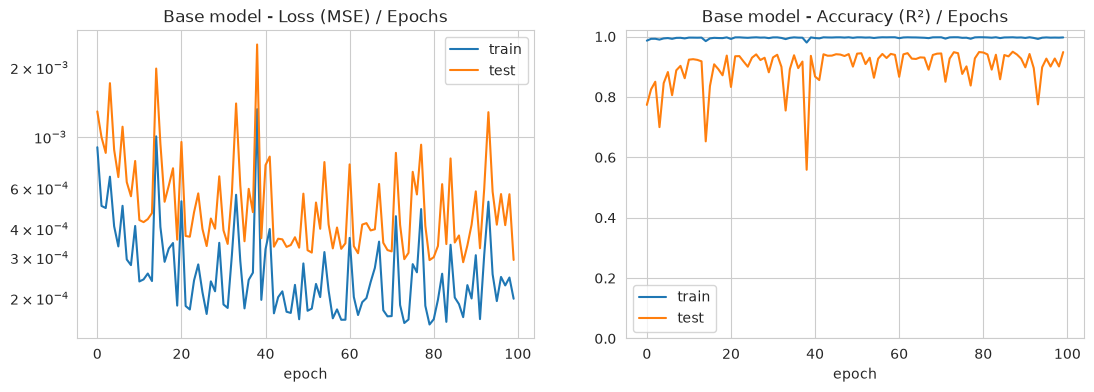

In [17]:
best = gs.best_params_
torch.manual_seed(42)
base_model = MLPRegressor(hidden=best["module__hidden"])
base_opt = best["optimizer"](base_model.parameters(), lr=best["lr"])
hist_base = train_model(base_model, base_opt, X_train, y_train, X_test, y_test, epochs=best["max_epochs"])
plot_history(hist_base, "Base model")

**Interpretation:**
- **Loss:** both train and test loss go down, so the model is learning. The test loss is a bit higher than the train loss, which is normal (the test data is new for the model). The test loss does not go up at the end, so there is no big overfitting.
- The curves have a lot of spikes. This is because the learning rate (0.01) is a bit high, so the model keeps "jumping" around the best solution.
- **Accuracy (R²):** on train it is almost 1 from the start. On test it is around 0.9, with some drops when the loss has a spike.
- **Final result on test:** R² = 0.949 and the average error is about 1.8 dollars per day.
- **But:** if we just say "tomorrow's price = today's price" we get an error of about 1.7 dollars, which is a little better. So the model did not really learn to predict the market, it mostly learned to copy the last price. In the plot below, the orange line is almost the blue line moved one day to the right.

In [18]:
def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        pred = model(torch.tensor(X)).numpy()
    # go back to real dollar prices
    pred_d = scaler.inverse_transform(pred)
    y_d = scaler.inverse_transform(y)
    return {
        "MSE": mean_squared_error(y_d, pred_d),
        "RMSE": np.sqrt(mean_squared_error(y_d, pred_d)),
        "MAE": mean_absolute_error(y_d, pred_d),
        "R2": r2_score(y_d, pred_d),
    }, pred_d


base_metrics, base_pred = evaluate(base_model, X_test, y_test)
print("Base model on test:", base_metrics)

# naive baseline: tomorrow's price = today's price
naive = scaler.inverse_transform(X_test[:, -1].reshape(-1, 1))
print("Naive baseline (yesterday's close) RMSE:", np.sqrt(mean_squared_error(scaler.inverse_transform(y_test), naive)))

Base model on test: {'MSE': 3.2649190425872803, 'RMSE': np.float64(1.8069086979112365), 'MAE': 1.3072704076766968, 'R2': 0.9485652446746826}
Naive baseline (yesterday's close) RMSE: 1.6803498847240603


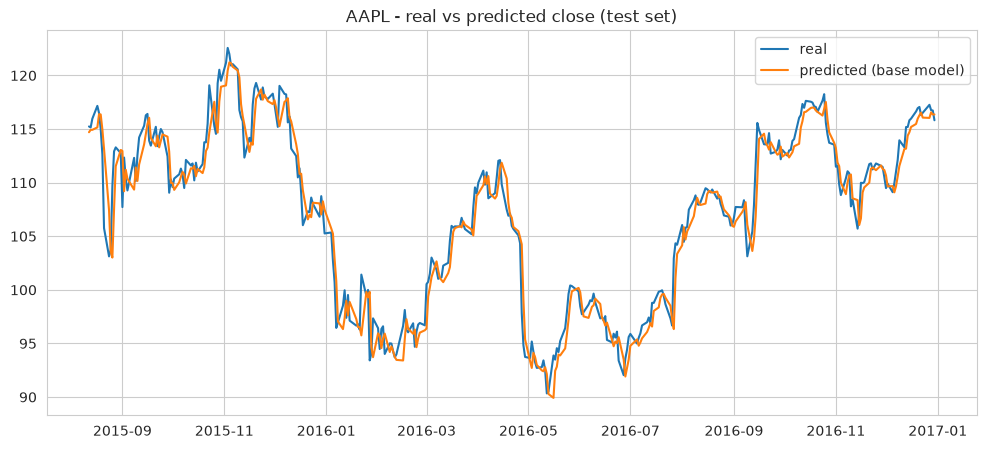

In [19]:
plt.figure(figsize=(12, 5))
plt.plot(dates_test, scaler.inverse_transform(y_test), label="real")
plt.plot(dates_test, base_pred, label="predicted (base model)")
plt.title("AAPL - real vs predicted close (test set)")
plt.legend()
plt.show()

Note: the naive baseline "tomorrow = today" is very hard to beat on stock prices (prices are close to a random walk).
So a good R² is not enough to say the model can "predict the market"; it mostly learned that the next price is
near the last one.

## 5. Regularization

We try several techniques on the same architecture and compare with the base model:
- **Dropout** (0.2): randomly turn off neurons during training
- **L2 / weight decay** (1e-4): penalize big weights
- **Batch Normalization**: normalize the activations of each layer
- **Early stopping**: stop when the test loss stops improving
- **All combined**

In [20]:
configs = {
    "Dropout":        dict(dropout=0.2, batchnorm=False, wd=0.0, patience=None),
    "L2 (weight decay)": dict(dropout=0.0, batchnorm=False, wd=1e-4, patience=None),
    "BatchNorm":      dict(dropout=0.0, batchnorm=True, wd=0.0, patience=None),
    "Early stopping": dict(dropout=0.0, batchnorm=False, wd=0.0, patience=10),
    "All combined":   dict(dropout=0.2, batchnorm=True, wd=1e-4, patience=10),
}

histories = {"Base": hist_base}
scores = {"Base": base_metrics}

for name, c in configs.items():
    torch.manual_seed(42)
    m = MLPRegressor(hidden=best["module__hidden"], dropout=c["dropout"], batchnorm=c["batchnorm"])
    opt = best["optimizer"](m.parameters(), lr=best["lr"], weight_decay=c["wd"])
    histories[name] = train_model(m, opt, X_train, y_train, X_test, y_test,
                                  epochs=best["max_epochs"], patience=c["patience"])
    scores[name], _ = evaluate(m, X_test, y_test)

Early stopping at epoch 37
Early stopping at epoch 32


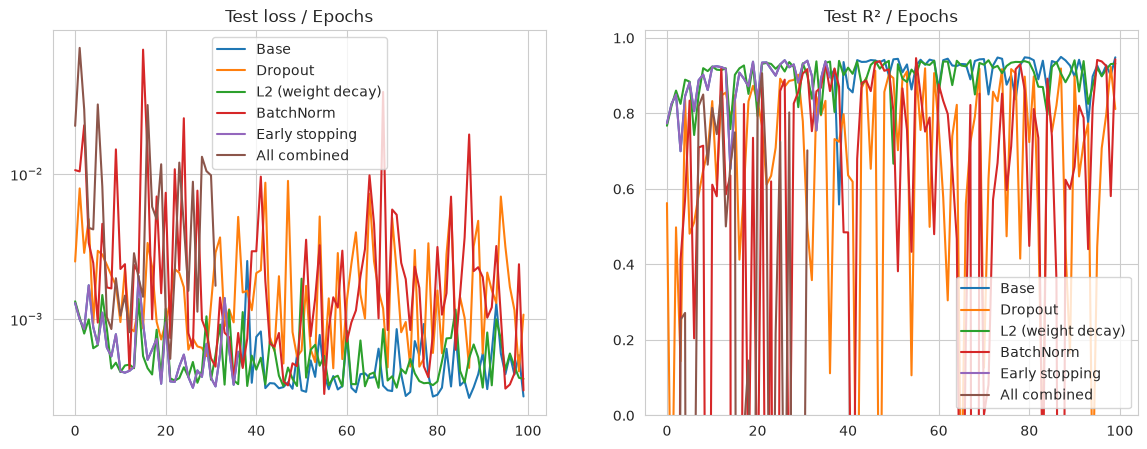

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, h in histories.items():
    ax[0].plot(h["test_loss"], label=name)
    ax[1].plot(h["test_r2"], label=name)
ax[0].set_title("Test loss / Epochs")
ax[0].set_yscale("log")
ax[1].set_title("Test R² / Epochs")
ax[1].set_ylim(0, 1.02)
ax[0].legend()
ax[1].legend()
plt.show()

In [22]:
comparison = pd.DataFrame(scores).T.round(4)
comparison

,MSE,RMSE,MAE,R2
Base,3.2649,1.8069,1.3073,0.9486
Dropout,11.9601,3.4583,2.9839,0.8116
L2 (weight decay),4.3198,2.0784,1.5151,0.9319
BatchNorm,3.5912,1.8950,1.4342,0.9434
Early stopping,3.7501,1.9365,1.4063,0.9409
All combined,5.9306,2.4353,1.8964,0.9066


**Comparison:**
- No regularization was better than the base model here. The base model is small and does not overfit much, so regularization has nothing to fix.
- **Dropout** is the worst (R² = 0.81). It turns off random neurons, which adds noise, and for regression we need precise numbers.
- **BatchNorm** gives almost the same score as the base model (0.943) but its curves are very unstable.
- **L2** has the smoothest curve but is a bit worse (0.932), because it keeps the weights small and the model becomes a bit too simple.
- **Early stopping** stops at epoch 37 with a score close to the base model (0.941), so we save training time.
- **All combined** stops at epoch 32 and gets 0.907: too much regularization for an easy problem.
- Small note: here early stopping watches the test set. The correct way is to use a separate validation set.